# 12. Ensemble Boosting Classifier (AdaBoost / Gradient Boosting) & Đánh giá ROC-AUC

## Lý thuyết & Nguyên lý

### 12.1. AdaBoost — tăng trọng số cho mẫu bị phân loại sai

AdaBoost (Adaptive Boosting) huấn luyện tuần tự các **weak learner** (thường là cây rất nông, `max_depth=1` — "stump"). Ở vòng $t$:

1. Huấn luyện learner $h_t$ trên dữ liệu với **trọng số mẫu** $w_i^{(t)}$ — mẫu nào bị phân loại sai ở vòng trước sẽ được **tăng trọng số**, buộc learner tiếp theo tập trung sửa chúng.
2. Tính **tỉ lệ lỗi** có trọng số: $\varepsilon_t = \dfrac{\sum_i w_i^{(t)}\,\mathbb{1}[y_i \ne h_t(x_i)]}{\sum_i w_i^{(t)}}$
3. Tính **trọng số của learner** (tương ứng "uy tín"): $\alpha_t = \dfrac{1}{2}\ln\!\left(\dfrac{1-\varepsilon_t}{\varepsilon_t}\right)$ — learner chính xác hơn có trọng số cao hơn.
4. Cập nhật trọng số mẫu: $w_i^{(t+1)} = w_i^{(t)}\, \exp\!\big(-\alpha_t\, y_i\, h_t(x_i)\big)$ (với $y_i \in \{-1, +1\}$), rồi chuẩn hóa.

Dự đoán cuối cùng là **tổng có trọng số** các learner:

$$\hat{y}(x) = \operatorname{sign}\left(\sum_{t=1}^{T} \alpha_t\, h_t(x)\right)$$

### 12.2. Gradient Boosting Classifier

Cùng khung với Gradient Boosting regression, nhưng cập nhật theo gradient của **Log Loss**:

$$F_m(x) = F_{m-1}(x) - \eta \cdot \frac{\partial L(y, F)}{\partial F}\bigg|_{F=F_{m-1}}, \qquad L = -\big[y\log p + (1-y)\log(1-p)\big]$$

Gradient của Log Loss chính là **sai số xác suất** $(\hat{p} - y)$ — mỗi cây mới học một bước điều chỉnh hướng giảm loss. XGBoost/LightGBM/CatBoost là các hiện thực Gradient Boosting tối ưu hóa phần cứng/thuật toán (histogram, cache, phân tán...), còn **nguyên lý cốt lõi vẫn là trên**.

### 12.3. Đánh giá ROC-AUC

**ROC curve** vẽ quan hệ giữa hai chỉ số khi **điều chỉnh ngưỡng phân loại** $t$ (từ 0 đến 1):

$$\text{TPR (Recall)} = \frac{TP}{TP + FN} \qquad \text{FPR} = \frac{FP}{FP + TN}$$

- $t$ cao (chỉ nhận khi rất tự tin) → TPR, FPR cùng thấp (góc dưới trái).
- $t$ thấp (nhận cả khi mơ hồ) → TPR, FPR cùng cao (góc trên phải).
- Đường chéo từ gốc tới $(1,1)$ = **phân loại ngẫu nhiên**, AUC = 0.5.

**AUC (Area Under Curve)** = xác suất một điểm **dương ngẫu nhiên** được chấm điểm cao hơn một điểm âm ngẫu nhiên. AUC = 1 hoàn hảo; AUC ≥ 0.7 thường chấp nhận được; AUC **không phụ thuộc ngưỡng** → rất phù hợp so sánh mô hình và với dữ liệu lệch lớp (khi đó accuracy gây hiểu nhầm — mô hình đoán cả về lớp thiểu số vẫn đạt accuracy cao).

**Chọn ngưỡng thực tế:** điểm tối ưu của Youden's $J = \text{TPR} - \text{FPR}$; hoặc chọn theo chi phí FN/FP của bài toán (y tế: ưu tiên TPR cao; phát hiện gian lận: ưu tiên FPR thấp).


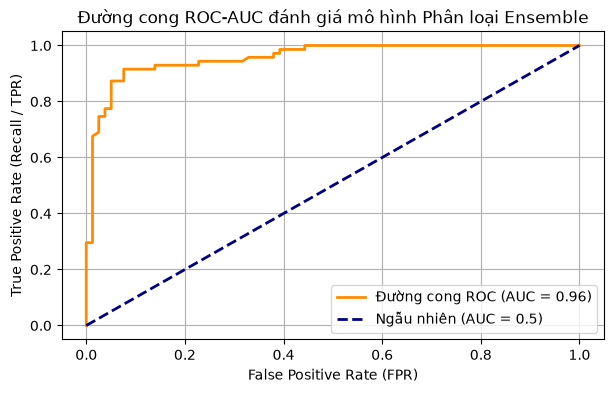

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import train_test_split

# 1. Tạo dữ liệu phân loại 10 đặc trưng
X, y = make_classification(n_samples=500, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 2. Huấn luyện AdaBoost và tính xác suất lớp dương
model = AdaBoostClassifier(random_state=42).fit(X_train, y_train)
y_score = model.predict_proba(X_test)[:, 1]

# 3. Tính đường cong ROC và diện tích AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 4))
plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'Đường cong ROC (AUC = {roc_auc:.2f})',
)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Ngẫu nhiên (AUC = 0.5)')
plt.title('Đường cong ROC-AUC đánh giá mô hình Phân loại Ensemble')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (Recall / TPR)')
plt.legend()
plt.grid(True)
plt.show()


## Ý nghĩa của biểu đồ

- Đường **cam** là ROC — đi sát góc trên bên trái nghĩa là mô hình đạt **TPR cao đồng thời FPR thấp** ở hầu hết mọi ngưỡng.
- Đường **xanh đứt** là đường chéo ngẫu nhiên (AUC = 0.5) — dùng làm mặt bằng so sánh; khoảng cách giữa đường cam và đường chéo là "giá trị gia tăng" mô hình mang lại.
- AUC ≈ 0.9+ cho AdaBoost trên dữ liệu `make_classification` (dễ tách lớp) — mô hình phân biệt dương/giảm rất tốt bất kể chọn ngưỡng nào.

---

## Tổng quan mô hình

### AdaBoost

**Ưu điểm:** đơn giản, mạnh trên dữ liệu trung bình; ít siêu tham số; hoạt động tốt với dữ liệu tuyến tính và phi tuyến; cung cấp `feature_importances_`.
**Nhược điểm:** **nhạy cảm mạnh với điểm ngoại lai và dữ liệu nhiễu** (vì tăng trọng số cho mẫu khó → outlier bị "kéo" theo); dễ overfitting khi learner quá mạnh; dữ liệu lệch lớp cần `class_weight`.

### Gradient Boosting / XGBoost

**Ưu điểm:** top performance trên tabular data; linh hoạt hàm mất mát; xử lý missing value; `feature_importances_`; nhiều thư viện tối ưu hiệu năng (XGBoost, LightGBM, CatBoost).
**Nhược điểm:** nhiều tham số (`learning_rate`, `n_estimators`, `max_depth`, `subsample`, `colsample_bytree`...); dễ overfitting; huấn luyện tuần tự; nhạy outlier (với squared/log loss chuẩn).

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `n_estimators` | Số learner/ cây boosting | 50–500 (AdaBoost), 100–3000 (GBM) |
| `learning_rate` | Bước sửa lỗi (shrinkage) | 0.01–0.2; đánh đổi với `n_estimators` |
| `max_depth` | Độ sâu mỗi cây | GBM: 3–5; AdaBoost stumps: 1 |
| `subsample` | Tỷ lệ mẫu mỗi vòng (Stochastic GB) | 0.5–1.0; giảm variance |
| `min_samples_leaf` | Số mẫu tối thiểu trong lá | Tăng lên giúp mượt, chống overfit |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Nhãn ($Y$) / Đánh giá |
| :--- | :--- | :--- | :--- |
| **Tài chính** | Phát hiện gian lận thẻ | Giao dịch, thiết bị, hành vi | Fraud/Bình thường — **AUC quan trọng hơn accuracy** |
| **Y tế** | Sàng lọc bệnh từ xét nghiệm | Chỉ số lâm sàng, dân số | Bệnh/Khỏe — chọn ngưỡng ưu tiên Recall |
| **Marketing** | Dự xác suất khách hàng phản hồi | Hành vi, nhân khẩu, lịch sử | Có phản hồi/AUC & Lift |
| **Khoa dữ liệu Kaggle** | Phân loại bảng nhiều đặc trưng | Hỗn hợp số + mã hóa categorical | Nhãn lớp — AUC là metric mặc định |
| **Chất lượng** | Phát hiện phế phẩm sản xuất | Đặc trưng cảm biến quá trình | Đạt/Lỗi — ưu tiên Recall cao |

### Mẹo thực hành

- **Dữ liệu lệch lớp** (fraud, bệnh hiếm): đừng tin accuracy — dùng **AUC-ROC** hoặc **AUC-PR (Precision-Recall)** làm tiêu chí chính.
- AdaBoost (`algorithm='SAMME'`) với stump: baseline boosting nhanh, dễ hiểu; sau đó nâng cấp lên GradientBoosting/XGBoost khi cần thêm hiệu năng.
- Chọn ngưỡng phân loại **không phải mặc định 0.5** — vẽ đường ROC/PR, chọn theo chi phí lỗi FN/FP hoặc Youden's J.


--- Gradient Boosting ---
Confusion Matrix (ngưỡng 0.5):
[[113  17]
 [ 16  94]]


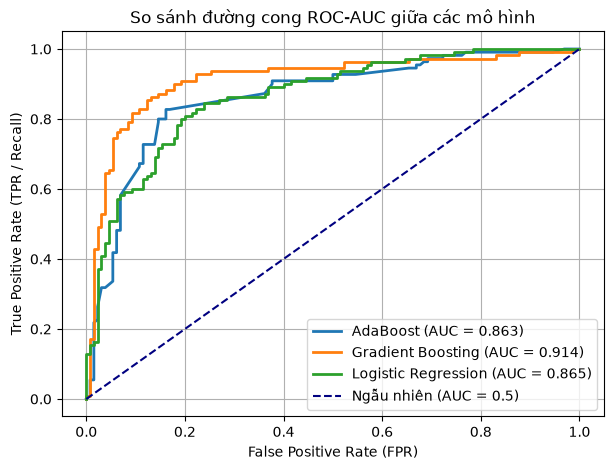

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split

# 1. Dữ liệu 800 mẫu, 10 đặc trưng (6 đặc trưng có ý nghĩa), có chút nhiễu nhãn
X, y = make_classification(
    n_samples=800, n_features=10, n_informative=6,
    flip_y=0.05, random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 2. So sánh 3 mô hình trên cùng đường cong ROC
models = {
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000),
}

plt.figure(figsize=(7, 5))
for name, model in models.items():
    model.fit(X_train, y_train)
    y_score = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')
    if name == 'Gradient Boosting':
        y_pred = (y_score >= 0.5).astype(int)
        print(f"--- {name} ---")
        print(f"Confusion Matrix (ngưỡng 0.5):\n{confusion_matrix(y_test, y_pred)}")

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Ngẫu nhiên (AUC = 0.5)')
plt.title('So sánh đường cong ROC-AUC giữa các mô hình')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


## Giải thích kết quả

- Cả ba mô hình đều có AUC **đáng kể hơn 0.5** — chứng tỏ mỗi mô hình đều học được tín hiệu thật từ dữ liệu.
- **Gradient Boosting / AdaBoost** thường vượt Logistic Regression về AUC khi dữ liệu có **phi tuyến/tương tác** giữa các đặc trưng; Logistic Regression nhanh hơn và là baseline không thể bỏ qua.
- **Confusion Matrix** in ra cho thấy tỷ lệ TP/TN/FP/FN cụ thể tại ngưỡng 0.5 — lưu ý: ngưỡng này chỉ là **mặc định**, không phải tối ưu. Nếu bài toán có chi phí FN/FP khác nhau, hãy chọn lại ngưỡng trên đường ROC (hoặc đường Precision-Recall).

**Tổng kết phần Phân loại:** bộ công cụ chuẩn của bạn giờ đã gồm — Logistic Regression (baseline tuyến tính), KNN (phi tham số, đơn giản), Decision Tree & Random Forest (phi tuyến, giải thích được), SVM (mạnh khi dữ liệu nhỏ/chiều cao/phi tuyến), Naïve Bayes (rất nhanh, văn bản), và Boosting (top performance trên tabular) — cùng bộ chỉ số ROC-AUC để đánh giá công bằng giữa chúng.
